# Problem 4: Metropolis–Hastings in two dimensions

We repeat Problem 2 with a state vector $z=(x,y)$, first for a correlated Gaussian and then for a rectangular uniform density. Each run uses 50,000 transitions. We show both one-dimensional marginal histograms and a two-dimensional scatter plot. Only NumPy and Matplotlib are needed.

## Two target densities

**(a) Correlated Gaussian.** The problem specifies the covariance matrix but leaves the mean unspecified. We choose $\mu=(2,2)$, carrying forward the mean from Problem 2:
$$V=\begin{pmatrix}2&1.2\\1.2&2\end{pmatrix},\qquad
p_G(z)=\frac{\exp[-\tfrac12(z-\mu)^T V^{-1}(z-\mu)]}{2\pi\sqrt{\det V}}.$$
Each marginal is $\mathcal N(2,2)$, with standard deviation $\sqrt2$. The correlation is $1.2/\sqrt{2\cdot2}=0.6$. We initialize at $(0,0)$ as the two-dimensional counterpart of Problem 2.

**(b) Rectangular uniform density.** The area is $(7-3)(9-1)=32$, so
$$p_R(x,y)=\begin{cases}1/32,&3<x<7\text{ and }1<y<9,\\0,&\text{otherwise}.\end{cases}$$
The marginal densities are $1/4$ on $(3,7)$ for $x$ and $1/8$ on $(1,9)$ for $y$. The mean is $(5,5)$ and the covariance is $\operatorname{diag}(4/3,16/3)$. Here $x$ and $y$ are independent. Initialize at $(5,5)$, where the target density is positive, as in Problem 3.

## One sampler for both targets

Propose both coordinates together:
$$z'=z+\epsilon,\qquad \epsilon\sim\mathcal N_2(0,I).$$
Two independent standard normal increments give exactly the identity proposal covariance. This symmetric proposal cancels from the Metropolis–Hastings ratio, so the same log acceptance test applies:
$$\log u<\min(0,\ell(z')-\ell(z)),\qquad u\sim U(0,1).$$
The log density can omit its normalization constant. For the rectangle it is 0 inside and $-\infty$ outside. A proposal is accepted or rejected as a whole vector; on rejection we store the previous vector again. All states after transitions are retained, with no burn-in discarded.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sample(log_p, start, rng):
    z = np.array(start, dtype=float)
    chain = np.empty((50_000, 2))
    accepted = 0
    for i in range(len(chain)):
        proposal = z + rng.normal(size=2)
        if np.log(rng.random()) < min(0.0, log_p(proposal) - log_p(z)):
            z = proposal
            accepted += 1
        chain[i] = z
    return chain, accepted / len(chain)

mean = np.array([2.0, 2.0])
V = np.array([[2.0, 1.2], [1.2, 2.0]])
V_inv = np.linalg.inv(V)

def log_gaussian(z):
    d = z - mean
    return -0.5 * d @ V_inv @ d

def log_rectangle(z):
    x, y = z
    return 0.0 if 3 < x < 7 and 1 < y < 9 else -np.inf

In [2]:
rng = np.random.default_rng(42)
gaussian, gaussian_acceptance = sample(log_gaussian, [0, 0], rng)
rectangle, rectangle_acceptance = sample(log_rectangle, [5, 5], rng)
runs = [("Gaussian", gaussian, gaussian_acceptance),
        ("Rectangle", rectangle, rectangle_acceptance)]
for name, chain, acceptance in runs:
    print(f"{name}: mean = {chain.mean(axis=0).round(4)}, acceptance = {acceptance:.3f}")
    print("Sample covariance:\n", np.cov(chain, rowvar=False, ddof=0).round(4))

Gaussian: mean = [1.9816 1.9634], acceptance = 0.608
Sample covariance:
 [[2.0149 1.1978]
 [1.1978 1.9847]]
Rectangle: mean = [5.0008 5.0583], acceptance = 0.720
Sample covariance:
 [[ 1.3315 -0.0108]
 [-0.0108  5.385 ]]


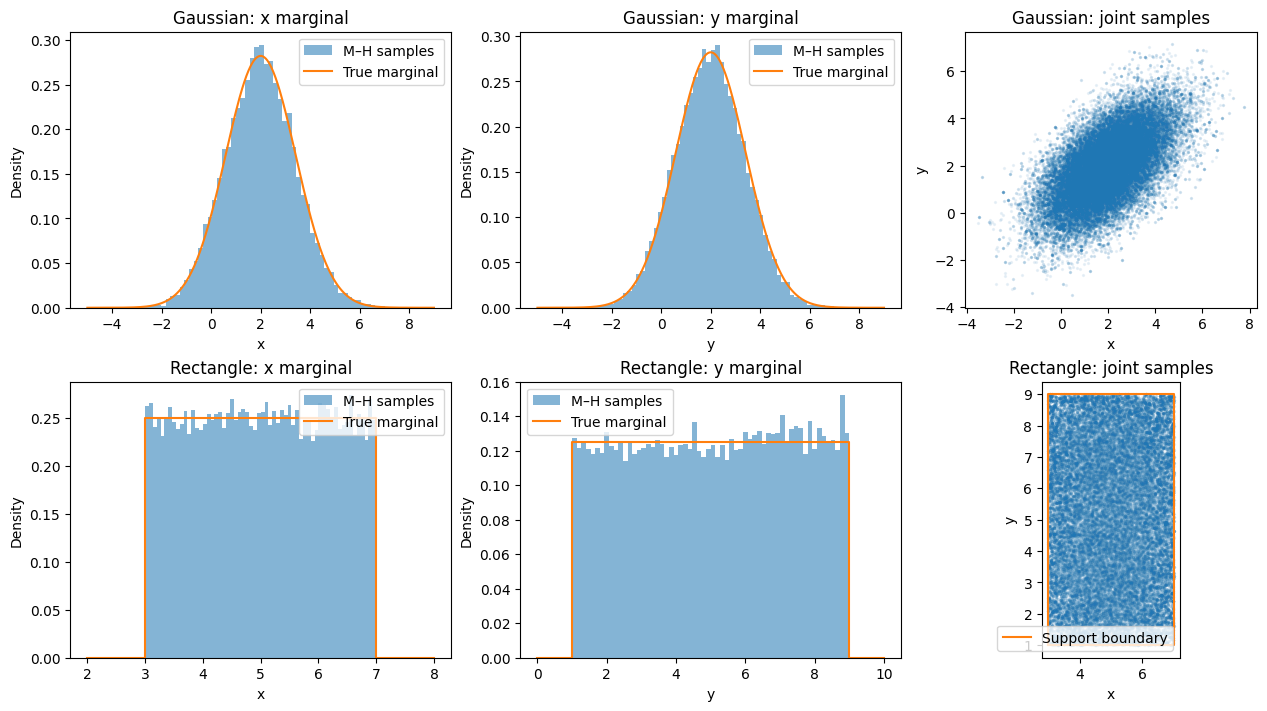

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for row, (name, chain, _) in enumerate(runs):
    for j, coordinate in enumerate(("x", "y")):
        ax = axes[row, j]
        ax.hist(chain[:, j], bins=60, density=True, alpha=0.55, label="M–H samples")
        if row == 0:
            grid = np.linspace(-5, 9, 500)
            density = np.exp(-(grid - 2) ** 2 / 4) / np.sqrt(4 * np.pi)
            ax.plot(grid, density, color="tab:orange", label="True marginal")
        else:
            lo, hi = [(3, 7), (1, 9)][j]
            ax.plot([lo-1, lo, lo, hi, hi, hi+1], [0, 0, 1/(hi-lo), 1/(hi-lo), 0, 0],
                    color="tab:orange", label="True marginal")
        ax.set(title=f"{name}: {coordinate} marginal", xlabel=coordinate, ylabel="Density")
        ax.legend()
    ax = axes[row, 2]
    ax.scatter(chain[:, 0], chain[:, 1], s=2, alpha=0.08, rasterized=True)
    if row == 1:
        ax.plot([3, 7, 7, 3, 3], [1, 1, 9, 9, 1], color="tab:orange", label="Support boundary")
        ax.legend()
    ax.set(title=f"{name}: joint samples", xlabel="x", ylabel="y")
    ax.set_aspect("equal", adjustable="box")
plt.show()

## What do the plots show?

For the Gaussian, both marginal histograms resemble the same $\mathcal N(2,2)$ density. The scatter plot adds information that the marginals cannot show: an elongated cloud tilted upward, reflecting the positive correlation of 0.6. Different joint distributions can share the same marginals.

For the rectangle, both marginals are approximately flat within their intervals. The scatter fills the allowed rectangle without a preferred tilt; the target coordinates are independent. Proposals crossing any boundary reject the entire move. The two histogram heights differ because each marginal must integrate to 1 over its own interval.

Sample means and covariance matrices fluctuate around their analytic values. Both chains have correlation **over time**, even though the rectangular target has no correlation **between coordinates**. Retaining rejected moves is essential to preserving the correct time spent in each region. These plots are useful checks, rather than a complete convergence assessment.